In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [9]:
df = pd.read_csv('customers.csv')
df.head(10)

,customer_id,region,tenure_days,orders_90d,avg_discount_90d,spend_90d,repeat_next_30d
0,1,North,646,4,0.121,362.68,1
1,2,West,364,0,0.223,0.00,0
2,3,East,720,2,0.121,332.34,0
3,4,South,563,4,0.139,541.88,1
4,5,South,486,2,0.014,195.82,1
5,6,West,663,2,0.321,227.89,0
6,7,North,391,0,0.142,0.00,0
7,8,East,535,3,0.115,201.61,1
8,9,North,229,4,0.030,219.06,0
9,10,North,705,2,0.222,74.17,0


In [10]:
numeric_features = [
    "tenure_days",
    "orders_90d",
    "spend_90d",
    "avg_discount_90d"
]
categorical_features = ["region"]

X= df[numeric_features + categorical_features]
y = df["repeat_next_30d"]

X_train, X_test, y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

In [11]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(),numeric_features),
    (
        "category",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train,y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('category', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [12]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [13]:
def evaluate(name, estimator):
    predictions = estimator.predict(X_test)
    probabilities = estimator.predict_proba(X_test)[:,1]

    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate("Dummy baseline", baseline),
    evaluate("Logistic regression", model)
]).set_index("model")

print(results.round(3))

                     ROC-AUC  precision  recall
model                                          
Dummy baseline         0.500      0.000   0.000
Logistic regression    0.711      0.667   0.235


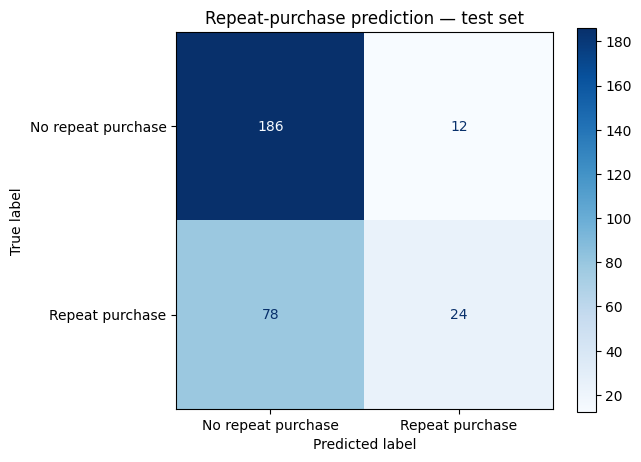

In [14]:
predictions = model.predict(X_test)

matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["No repeat purchase", "Repeat purchase"]
).plot(cmap="Blues", values_format="d")

plt.title("Repeat-purchase prediction — test set")
plt.tight_layout()
plt.show()